# NLP Project Phase 1: Exploration, Tokenization & Cleaning
**Dataset:** IMDB Dataset of 50K Movie Reviews (binary sentiment: positive / negative)

This notebook covers Task 2 (exploration), Task 3 (tokenization and regex) and Task 4 (cleaning pipeline).
Run it from the `notebooks/` folder after `python src/load_data.py`.

In [1]:
import sys, re, time, json, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
import cleaning as C
from load_data import load_raw

FIG = Path("../output/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = load_raw()
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Task 2: Exploration and basic statistics

In [2]:
print("Documents:", f"{len(df):,}")
print("Missing values:\n", df.isna().sum().to_string())
print("Exact duplicate reviews:", df.duplicated(subset="review").sum())

df["n_chars"] = df["review"].str.len()
df["n_words"] = df["review"].str.split().str.len()
print("\nAverage length: %.0f characters, %.1f words" % (df.n_chars.mean(), df.n_words.mean()))
print("Median words: %d | min: %d | max: %d" % (df.n_words.median(), df.n_words.min(), df.n_words.max()))
print("\nLength by class (words):")
print(df.groupby("sentiment")["n_words"].describe()[["mean", "50%", "max"]].round(1).to_string())

Documents: 50,000
Missing values:
 review       0
sentiment    0
Exact duplicate reviews: 418



Average length: 1309 characters, 231.2 words
Median words: 173 | min: 4 | max: 2470

Length by class (words):
            mean    50%     max
sentiment                      
negative   229.5  174.0  1522.0
positive   232.8  172.0  2470.0


Target distribution:
 sentiment
positive    25000
negative    25000
Balanced: True


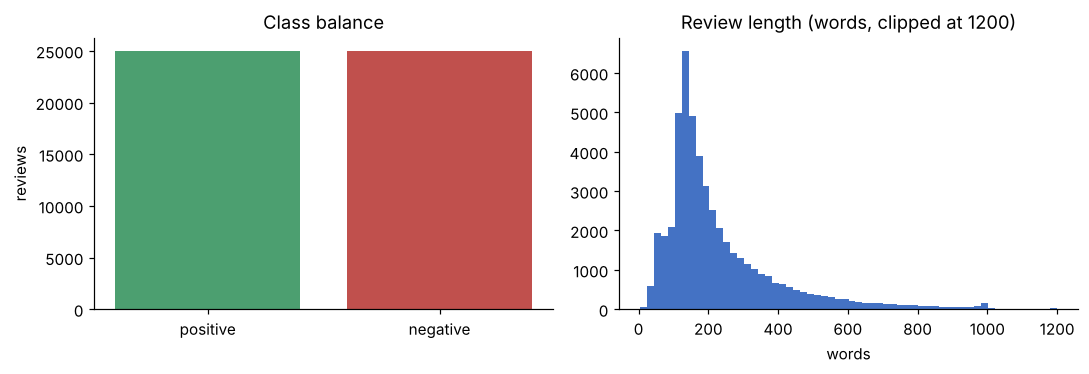

In [3]:
counts = df["sentiment"].value_counts()
print("Target distribution:\n", counts.to_string())
print("Balanced:", counts.min() == counts.max())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(counts.index, counts.values, color=["#4c9f70", "#c0504d"])
ax[0].set_title("Class balance"); ax[0].set_ylabel("reviews")
ax[1].hist(df["n_words"].clip(upper=1200), bins=60, color="#4472c4")
ax[1].set_title("Review length (words, clipped at 1200)"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.savefig(FIG / "class_and_length.png"); plt.show()

### Tokens vs types, vocabulary size and Zipf's law
For these statistics we use a light tokenization of the *raw* text: remove HTML tags, lower-case, keep letter runs
(with apostrophes). **Tokens** = all word occurrences. **Types** = unique words (the vocabulary).

In [4]:
html = C.HTML_RE
word_re = re.compile(r"[a-z]+(?:'[a-z]+)?")
freq = collections.Counter()
for text in df["review"]:
    freq.update(word_re.findall(html.sub(" ", text).lower()))

n_tokens = sum(freq.values()); n_types = len(freq)
hapax = sum(1 for c in freq.values() if c == 1)
print(f"Tokens: {n_tokens:,}")
print(f"Types (vocabulary size): {n_types:,}")
print(f"Type/token ratio: {n_types / n_tokens:.4f}")
print(f"Words appearing only once (hapax legomena): {hapax:,} ({100 * hapax / n_types:.1f}% of vocabulary)")

top = freq.most_common(20)
print("\nTop 20 words:", ", ".join(f"{w} ({c:,})" for w, c in top))
ranked = np.array([c for _, c in freq.most_common()])
cum = ranked.cumsum() / ranked.sum()
print(f"Top 100 types cover {100 * cum[99]:.1f}% of all tokens; top 1000 cover {100 * cum[999]:.1f}%")

Tokens: 11,485,517
Types (vocabulary size): 109,526
Type/token ratio: 0.0095
Words appearing only once (hapax legomena): 42,545 (38.8% of vocabulary)

Top 20 words: the (668,003), and (324,438), a (323,032), of (289,412), to (268,107), is (211,085), in (186,777), it (157,031), i (155,104), this (150,991), that (137,063), was (95,592), as (91,762), for (87,471), with (87,366), movie (87,162), but (83,552), film (77,758), on (68,068), not (60,746)
Top 100 types cover 50.7% of all tokens; top 1000 cover 76.4%


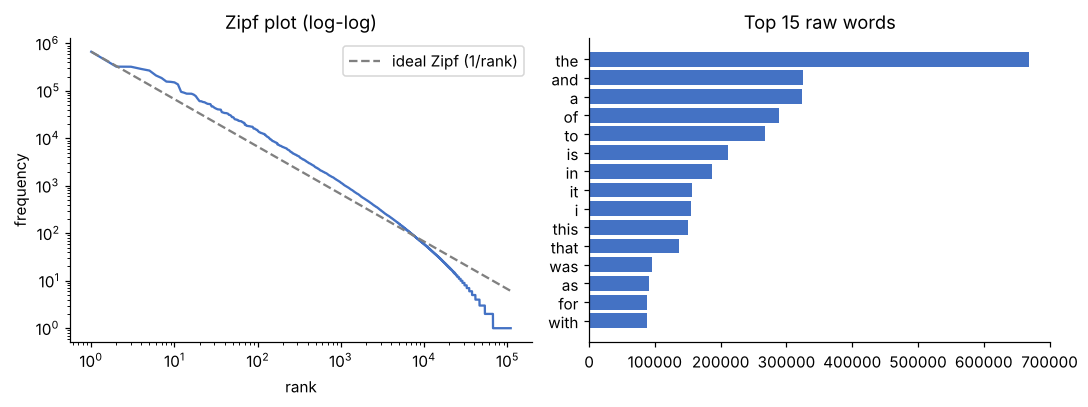

In [5]:
ranks = np.arange(1, len(ranked) + 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].loglog(ranks, ranked, color="#4472c4")
ref = ranked[0] / ranks
ax[0].loglog(ranks, ref, "--", color="gray", label="ideal Zipf (1/rank)")
ax[0].set_xlabel("rank"); ax[0].set_ylabel("frequency"); ax[0].set_title("Zipf plot (log-log)"); ax[0].legend()
labels, vals = zip(*top[:15])
ax[1].barh(labels[::-1], vals[::-1], color="#4472c4"); ax[1].set_title("Top 15 raw words")
plt.tight_layout(); plt.savefig(FIG / "zipf_and_top_words.png"); plt.show()

**Zipf's law / long tail.** The rank-frequency plot is close to a straight line on log-log axes, so a handful of
very frequent words (mostly function words such as *the, and, a, of*) account for a large share of all tokens,
while a very long tail of rare words, many appearing only once, makes up most of the vocabulary. This matters for
NLP: the tail is sparse and noisy (typos, names, elongated words), so cleaning that merges variants
(case folding, lemmatization, noise removal) shrinks the vocabulary a lot without losing much signal.

### Examples of messy text

In [6]:
def show(pattern, label, n=2, width=170):
    rx = re.compile(pattern)
    hits = df[df["review"].str.contains(rx)]
    print(f"--- {label}: {len(hits):,} reviews ({100 * len(hits) / len(df):.1f}%)")
    for t in hits["review"].head(n):
        m = rx.search(t); s = max(0, m.start() - 60)
        print("   ...", t[s:s + width].replace("\n", " "), "...")

show(r"<br\s*/?>", "HTML line breaks")
show(r"https?://\S+|www\.\S+", "URLs")
show(r"\b\d{1,2}(?:\.\d)?\s*/\s*10\b", "Numeric ratings like 8/10")
show(r"([A-Za-z])\1{3,}", "Elongated words (sooooo)")
show(r"\b[A-Z]{4,}\b", "ALL-CAPS shouting")
show(r"[^\x00-\x7F]", "Non-ASCII characters (accents, symbols)")

--- HTML line breaks: 29,200 reviews (58.4%)
   ... d. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, whic ...
   ... A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense  ...


--- URLs: 195 reviews (0.4%)
   ... EPTIC'S GUIDE TO AN INCONVENIENT TRUTH" can be found at is :www.cei.org. A shorter 10-page version can be found at: www.cei.org/pdf/5539.pdf Once you read those demolitio ...
   ...  pages of film.<br /><br />- A review by Jamie Robert Ward (http://www.invocus.net) ...


--- Numeric ratings like 8/10: 2,980 reviews (6.0%)
   ... ionally hilarious at the same time, I'm giving this movie a 3/10, an improvement from the 0.5/10 I was originally going to give it.<br /><br />(According to my grading sc ...
   ... fected by it.<br /><br />Just say no to this movie, though. 2/10. ...


/tmp/ipykernel_240/145035372.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hits = df[df["review"].str.contains(rx)]


--- Elongated words (sooooo): 681 reviews (1.4%)
   ... n- BOOM! the anime comes on! This is when the movie goes WWWAAAAAYYYYY downhill.<br /><br />The animation is VERY bad & cheap, even worse than what I remember from SPEED  ...
   ...  only briefly, the way it moves is the best! This movie is Waaaaaaaaaaay better than the Michael Keaton piece of crap, becuz that was made too be a good movie, and that v ...


--- ALL-CAPS shouting: 11,339 reviews (22.7%)
   ... loset which totally ruins all the film! I expected to see a BOOGEYMAN similar movie, and instead i watched a drama with some meaningless thriller spots.<br /><br />3 out  ...
   ... ng his top-secret research on an island that reminds me of "SPOILER" Vancouver for some reason. Thats right no palm trees here. Instead we got some nice rich lumberjack-w ...
--- Non-ASCII characters (accents, symbols): 4,660 reviews (9.3%)
   ... genre that has been done and redone so many times that clichéd dialogue, rehashed plot and over-the-top action sequences seem unavoidable for any conflict dealing with la ...
   ... taking place in Italian cinema since the decline of Cinecittà during the second half of the 70s. The world is waiting for Italy to produce more Il Postino-like fare, more ...


## Task 3: Tokenization and regular expressions
### Comparing tokenizers
We compare three approaches on a few tricky sentences, then on a 2,000-review sample:
1. **Whitespace split** (naive baseline)
2. **Regex tokenizer** (letter runs, keeping inner apostrophes; the pipeline uses the same idea, `[a-z]+`, after expanding contractions)
3. **NLTK `word_tokenize`** (Punkt + Treebank rules)

In [7]:
from nltk.tokenize import word_tokenize

def tok_ws(t): return t.split()
def tok_regex(t): return re.findall(r"[a-z]+(?:'[a-z]+)?", t.lower())
def tok_nltk(t): return word_tokenize(t)

tricky = [
    "I can't believe it's not better... 8/10, would NOT recommend!!!",
    "A so-called 'masterpiece' by Mr. Smith (1999) :) costing $5.50.",
    "Sooooo good!!! Visit www.imdb.com for more.",
]
for s in tricky:
    print("TEXT :", s)
    for name, f in [("whitespace", tok_ws), ("regex", tok_regex), ("nltk", tok_nltk)]:
        print(f"  {name:10s}", f(s))
    print()

TEXT : I can't believe it's not better... 8/10, would NOT recommend!!!
  whitespace ['I', "can't", 'believe', "it's", 'not', 'better...', '8/10,', 'would', 'NOT', 'recommend!!!']
  regex      ['i', "can't", 'believe', "it's", 'not', 'better', 'would', 'not', 'recommend']
  nltk       ['I', 'ca', "n't", 'believe', 'it', "'s", 'not', 'better', '...', '8/10', ',', 'would', 'NOT', 'recommend', '!', '!', '!']

TEXT : A so-called 'masterpiece' by Mr. Smith (1999) :) costing $5.50.
  whitespace ['A', 'so-called', "'masterpiece'", 'by', 'Mr.', 'Smith', '(1999)', ':)', 'costing', '$5.50.']
  regex      ['a', 'so', 'called', 'masterpiece', 'by', 'mr', 'smith', 'costing']
  nltk       ['A', 'so-called', "'", 'masterpiece', "'", 'by', 'Mr.', 'Smith', '(', '1999', ')', ':', ')', 'costing', '$', '5.50', '.']

TEXT : Sooooo good!!! Visit www.imdb.com for more.
  whitespace ['Sooooo', 'good!!!', 'Visit', 'www.imdb.com', 'for', 'more.']
  regex      ['sooooo', 'good', 'visit', 'www', 'imdb', 'com', 'fo

In [8]:
sample = df["review"].sample(2000, random_state=42).map(lambda t: C.HTML_RE.sub(" ", t))
rows = []
for name, f in [("whitespace", tok_ws), ("regex", tok_regex), ("nltk", tok_nltk)]:
    t0 = time.time(); toks = [f(t) for t in sample]; dt = time.time() - t0
    flat = [w.lower() for ts in toks for w in ts]
    rows.append({"tokenizer": name, "tokens": len(flat), "vocab (types)": len(set(flat)),
                 "avg tokens/review": round(len(flat) / len(toks), 1), "seconds": round(dt, 2)})
pd.DataFrame(rows).set_index("tokenizer")

,tokens,vocab (types),avg tokens/review,seconds
tokenizer,,,,
whitespace,459645,49370,229.8,0.04
regex,461553,26337,230.8,0.13
nltk,533330,28341,266.7,2.91


**Tokenization challenges observed**

1. **Contractions and negation.** `can't` / `don't` are split differently by each tokenizer (NLTK gives `ca` + `n't`,
   whitespace keeps `can't`, the regex keeps it whole). For sentiment this matters because *not good* and *good* have
   opposite meaning, so our pipeline expands contractions to `can not` and keeps `no/nor/not` as tokens.
2. **Punctuation glued to words.** Whitespace splitting produces `it.` and `great!!!` as separate vocabulary entries
   from `it` and `great`, which inflates the vocabulary and splits counts.
3. **Special strings** such as ratings (`8/10`), URLs, prices (`$5.50`), emoticons and hyphenated compounds
   (`so-called`) are handled inconsistently by general tokenizers and need dedicated regex rules.

### Regular expressions used in the pipeline

In [9]:
patterns = {
    "HTML tags":        (C.HTML_RE.pattern,   "Remove <br /> and other markup left by the web scrape"),
    "URLs":             (C.URL_RE.pattern,    "Remove links, they carry no sentiment"),
    "Numeric ratings":  (C.RATING_RE.pattern, "Remove 'x/10' ratings (digits are not kept as tokens)"),
    "Elongated letters":(C.REPEAT_RE.pattern, "Collapse 3+ repeated letters: sooooo -> soo"),
    "Letter tokens":    (C.TOKEN_RE.pattern,  "Tokenizer: keep alphabetic runs only"),
}
out = []
for name, (pat, why) in patterns.items():
    rx = re.compile(pat, re.I if name != "Elongated letters" else 0)
    n = sum(len(rx.findall(t if name != "Elongated letters" else t.lower())) for t in df["review"].head(5000))
    out.append({"regex": name, "pattern": pat, "matches in first 5,000 reviews": n, "purpose": why})
pd.DataFrame(out).set_index("regex")

,pattern,"matches in first 5,000 reviews",purpose
regex,,,
HTML tags,<[^>]+>,20627,Remove <br /> and other markup left by the web...
URLs,https?://\S+|www\.\S+,15,"Remove links, they carry no sentiment"
Numeric ratings,"\b\d{1,2}(?:\.\d)?\s*/\s*10\b",357,Remove 'x/10' ratings (digits are not kept as ...
Elongated letters,"([a-z])\1{2,}",192,Collapse 3+ repeated letters: sooooo -> soo
Letter tokens,[a-z]+,1191662,Tokenizer: keep alphabetic runs only


In [10]:
demo = "Loved it!!! <br /><br />Rating: 9/10, sooooo good. More at http://imdb.com/x"
s = C.strip_noise(C.normalize_unicode(demo))
print("before:", demo)
print("after :", s)

before: Loved it!!! <br /><br />Rating: 9/10, sooooo good. More at http://imdb.com/x
after : loved it!!!   rating:  , soo good. more at  


## Task 4: Cleaning and normalization pipeline
The reusable function is `cleaning.preprocess(text)` in `src/cleaning.py`. Steps are applied in this order and the
order matters:

| # | Step | Why this position |
|---|------|-------------------|
| 1 | Unicode normalization (NFKD, drop accents, unify quotes) | First, so every later regex sees consistent characters (`café` -> `cafe`, `’` -> `'`). |
| 2 | Noise removal (HTML, URLs, ratings) | Before tokenizing, otherwise `<br />` leaves a fake token `br`. |
| 3 | Case folding + elongated letters | `Movie` / `movie` become one type; done after HTML removal so tag names are gone. |
| 4 | Contraction expansion | Before tokenizing and stop-word removal, so `don't` becomes `do not` and the negation survives. |
| 5 | Tokenization (letters only, length ≥ 2) | Drops digits, punctuation and 's' leftovers. |
| 6 | Stop-word removal (NLTK list **minus** `no, nor, not`) | After tokenization; negations are kept because they flip sentiment. |
| 7 | **Lemmatization** (WordNet) | Last, on the reduced token list. We chose lemmatization over stemming because it returns real words (`movies` -> `movie`) and is easier to interpret. |

In [11]:
stages = {}
cur = df["review"].drop_duplicates().tolist()
stages["0. raw (whitespace tokens)"] = len({w for t in cur for w in t.split()})
cur = [C.normalize_unicode(t) for t in cur]
cur = [C.strip_noise(t) for t in cur]
cur = [C.expand_contractions(t) for t in cur]
toks = [C.tokenize(t) for t in cur]
stages["1-4. after unicode + noise + case + contractions + tokenize"] = len({w for ts in toks for w in ts})
toks = [C.remove_stopwords(ts) for ts in toks]
stages["5. after stop-word removal"] = len({w for ts in toks for w in ts})
toks = [C.lemmatize_tokens(ts) for ts in toks]
stages["6. after lemmatization (final)"] = len({w for ts in toks for w in ts})

res = pd.DataFrame({"vocabulary size": stages})
res["change vs raw"] = (100 * (res["vocabulary size"] / res["vocabulary size"].iloc[0] - 1)).round(1).astype(str) + " %"
res

,vocabulary size,change vs raw
0. raw (whitespace tokens),438729,0.0 %
1-4. after unicode + noise + case + contractions + tokenize,98628,-77.5 %
5. after stop-word removal,98491,-77.6 %
6. after lemmatization (final),79320,-81.9 %


Reviews after de-duplication: 49,582


Tokens before cleaning (whitespace): 11,470,804
Tokens after cleaning: 6,007,695


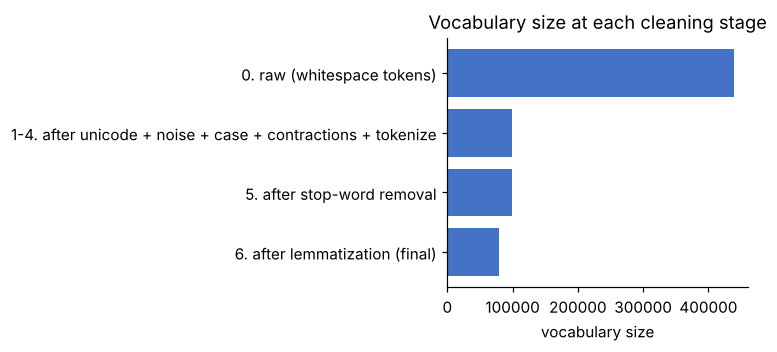

In [12]:
final_tokens = sum(len(t) for t in toks)
print(f"Reviews after de-duplication: {len(toks):,}")
print(f"Tokens before cleaning (whitespace): {df.drop_duplicates(subset='review')['review'].str.split().str.len().sum():,}")
print(f"Tokens after cleaning: {final_tokens:,}")

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.barh(list(stages.keys())[::-1], list(stages.values())[::-1], color="#4472c4")
ax.set_xlabel("vocabulary size"); ax.set_title("Vocabulary size at each cleaning stage")
plt.tight_layout(); plt.savefig(FIG / "vocab_reduction.png"); plt.show()

In [13]:
i = 0
raw = df["review"].drop_duplicates().iloc[i]
print("RAW  :", raw[:400].replace("\n", " "), "...")
print("CLEAN:", C.clean_text(raw)[:400], "...")

RAW  : One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to ...
CLEAN: one reviewer mention watch oz episode hook right exactly happen first thing strike oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use word call oz nickname give oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face inwards privac ...


## Task 5: Output and reproducibility
`python src/cleaning.py` writes `output/cleaned_data.csv` (columns: `orig_id, sentiment, label, clean_text, n_tokens`)
and `output/cleaning_stats.json`. Quick check of the saved file:

In [14]:
out = pd.read_csv("../output/cleaned_data.csv")
print(out.shape); print(out["label"].value_counts().to_string())
print(json.dumps(json.load(open("../output/cleaning_stats.json")), indent=2))
out.head()

(49582, 5)
label
1    24884
0    24698
{
  "rows_raw": 50000,
  "duplicates_removed": 418,
  "rows_empty_after_cleaning_removed": 0,
  "rows_final": 49582,
  "vocab_before_whitespace_tokens": 438729,
  "vocab_after_cleaning": 79320,
  "vocab_reduction_pct": 81.9,
  "avg_tokens_after_cleaning": 121.2
}


,orig_id,sentiment,label,clean_text,n_tokens
0,0,positive,1,one reviewer mention watch oz episode hook rig...,171
1,1,positive,1,wonderful little production film technique una...,88
2,2,positive,1,think wonderful way spend time hot summer week...,87
3,3,negative,0,basically family little boy jake think zombie ...,64
4,4,positive,1,petter mattei love time money visually stun fi...,127
